# PUBG 玩家排名预测 — 机器学习分析 (Plan)

**目标**：预测 `winPlacePerc`（排名百分位，1=第一名，0=最后一名）

**模型**：方案A 随机森林 + 方案B 决策树  
**评估标准**：R² Score > 0.925, MAE < 0.059

**环境**：Conda `machine-learning-aura`

## 0. 导入依赖

In [1]:
import numpy as np    # numpy：科学计算库，提供数组（ndarray）与数学函数
import pandas as pd   # pandas：数据分析库，DataFrame 是表格型数据结构，本项目的核心容器
import matplotlib.pyplot as plt  # matplotlib：绘图库，plt 负责画折线图、柱状图、饼图等
import seaborn as sns  # seaborn：基于 matplotlib 的高层绘图库，自带美观主题
import time            # time：时间模块，用来记录程序运行耗时
import warnings        # warnings：警告控制模块
warnings.filterwarnings('ignore')  # 忽略所有警告，保持输出整洁（不影响结果正确性）

# sklearn.model_selection：数据划分与调参工具
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, cross_validate  # 导入数据划分与调参工具
# train_test_split：把数据划分成训练集/验证集；RandomizedSearchCV：随机搜索超参数；
# cross_val_score / cross_validate：交叉验证评估模型
from sklearn.ensemble import RandomForestRegressor  # 随机森林回归器（多棵决策树的集成）
from sklearn.tree import DecisionTreeRegressor, plot_tree  # 决策树回归器；plot_tree 可把树画出来
from sklearn.metrics import r2_score, mean_absolute_error  # 回归评估指标：R² 决定系数、MAE 平均绝对误差
from sklearn.impute import SimpleImputer  # 缺失值填充器（用均值/中位数等策略填充 NaN）

plt.rcParams['figure.figsize'] = (12, 6)  # 全局设置：默认图幅 12x6 英寸
plt.rcParams['font.size'] = 12  # 全局设置：默认字体大小 12
# 中文字体设置（macOS：Arial Unicode MS / PingFang SC；Windows：SimHei / Microsoft YaHei）
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB', 'SimHei', 'Microsoft YaHei']  # 依次尝试这些字体，避免图里中文变方框
plt.rcParams['axes.unicode_minus'] = False  # 让坐标轴的负号“−”正常显示（否则可能显示成方块）
sns.set_style('whitegrid')  # 设置绘图风格：白底 + 网格线

print('All imports successful!')  # 提示：所有库导入成功


All imports successful!


## 1. 数据加载与初步探索

加载训练集，查看基本信息。test_V2.csv 无标签，仅用于 GitHub 提交预测，本次不加载。

In [2]:
# 加载训练数据（test_V2.csv 无标签，仅用于最终提交预测，本次不加载）
print('Loading train_V2.csv ...')  # 打印开始加载的提示
df_train = pd.read_csv('data/train_V2.csv')  # pandas 读取 CSV 文件 -> 存入 df_train（行=玩家，列=特征）
print(f'Train shape: {df_train.shape}')  # 打印数据形状 (行数, 列数)；f-string 可在字符串里插变量


Loading train_V2.csv ...
Train shape: (4446966, 29)


In [3]:
# 初步探索训练集
print('=== Train info ===')  # 打印标题分隔线
df_train.info()  # info() 汇总每列：名称、类型、非空数量、内存占用，快速了解数据全貌


=== Train info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4446966 entries, 0 to 4446965
Data columns (total 29 columns):
 #   Column           Dtype  
---  ------           -----  
 0   Id               object 
 1   groupId          object 
 2   matchId          object 
 3   assists          int64  
 4   boosts           int64  
 5   damageDealt      float64
 6   DBNOs            int64  
 7   headshotKills    int64  
 8   heals            int64  
 9   killPlace        int64  
 10  killPoints       int64  
 11  kills            int64  
 12  killStreaks      int64  
 13  longestKill      float64
 14  matchDuration    int64  
 15  matchType        object 
 16  maxPlace         int64  
 17  numGroups        int64  
 18  rankPoints       int64  
 19  revives          int64  
 20  rideDistance     float64
 21  roadKills        int64  
 22  swimDistance     float64
 23  teamKills        int64  
 24  vehicleDestroys  int64  
 25  walkDistance     float64
 26  weaponsAcquired  int64 

=== winPlacePerc stats ===
count    4.446965e+06
mean     4.728216e-01
std      3.074050e-01
min      0.000000e+00
25%      2.000000e-01
50%      4.583000e-01
75%      7.407000e-01
max      1.000000e+00
Name: winPlacePerc, dtype: float64


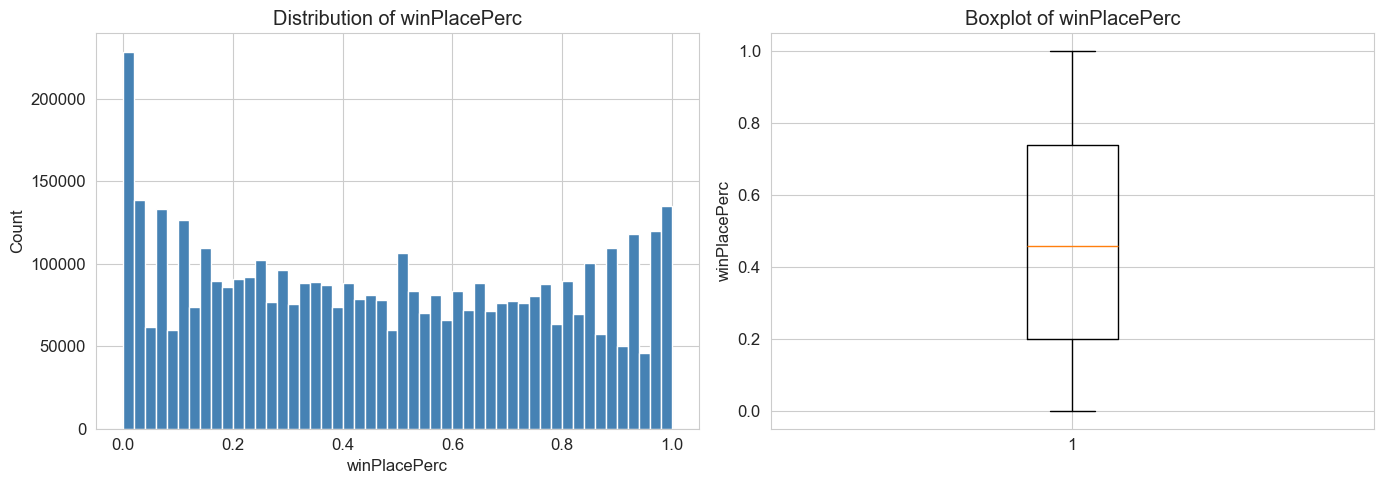

In [4]:
# 目标变量 winPlacePerc 的分布（我们要预测的就是“最终排名百分位”）
print('=== winPlacePerc stats ===')  # 打印标题
print(df_train['winPlacePerc'].describe())  # describe() 输出统计量：个数/均值/标准差/min/四分位数/max

fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # 创建 1 行 2 列的子图；fig=整张画布，axes=[左子图, 右子图]

# —— 左子图：直方图（看分布形状）——
axes[0].hist(df_train['winPlacePerc'], bins=50, color='steelblue', edgecolor='white')  # hist 画直方图；bins=50 分成 50 个区间
axes[0].set_title('Distribution of winPlacePerc')  # 子图标题
axes[0].set_xlabel('winPlacePerc')  # x 轴标签
axes[0].set_ylabel('Count')  # y 轴标签（频数）

# —— 右子图：箱线图（看分位数与异常值）——
axes[1].boxplot(df_train['winPlacePerc'].dropna(), vert=True)  # boxplot 画箱线图；dropna() 先去掉缺失值
axes[1].set_title('Boxplot of winPlacePerc')  # 子图标题
axes[1].set_ylabel('winPlacePerc')  # y 轴标签

plt.tight_layout()  # 自动调整子图间距，避免标题/标签重叠
plt.show()  # 显示图形


In [5]:
# 缺失值统计
print('=== Missing values in train ===')  # 打印标题
missing = df_train.isnull().sum()  # isnull() 逐位置判断是否缺失；sum() 按列求和 -> 得到每列缺失数量
missing_pct = (missing / len(df_train) * 100).round(2)  # 每列缺失比例（%），保留 2 位小数
missing_df = pd.DataFrame({'Count': missing, 'Percentage(%)': missing_pct})  # 两列信息合并成一个 DataFrame
print(missing_df[missing_df['Count'] > 0].sort_values('Count', ascending=False))  # 只看有缺失的列，按缺失数从多到少


=== Missing values in train ===
              Count  Percentage(%)
winPlacePerc      1            0.0


=== matchType distribution ===
matchType
squad-fpp           1756186
duo-fpp              996691
squad                626526
solo-fpp             536762
duo                  313591
solo                 181943
normal-squad-fpp      17174
crashfpp               6287
normal-duo-fpp         5489
flaretpp               2505
normal-solo-fpp        1682
flarefpp                718
normal-squad            516
crashtpp                371
normal-solo             326
normal-duo              199
Name: count, dtype: int64


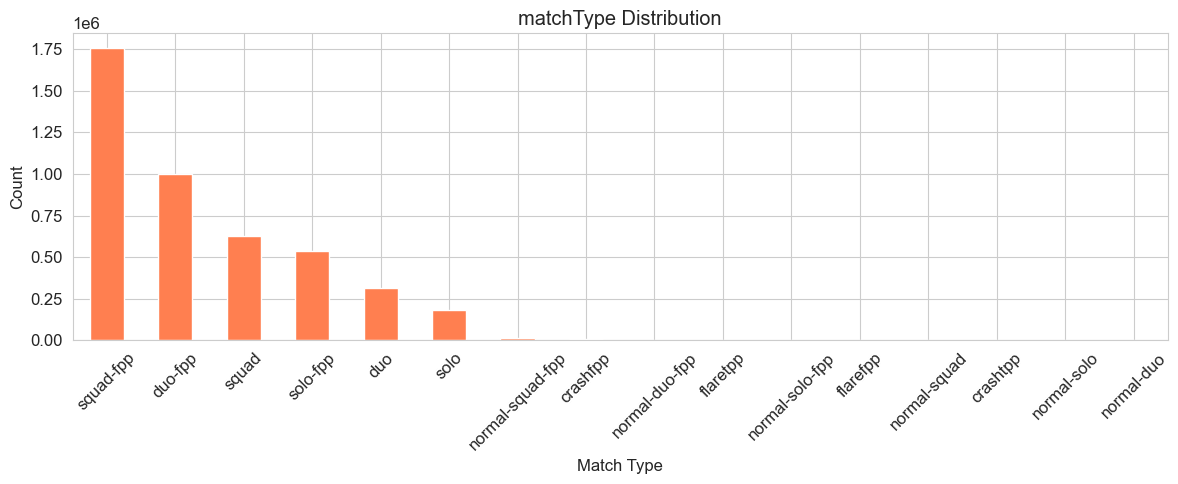

In [6]:
# matchType 分布（对局模式）
print('=== matchType distribution ===')  # 打印标题
print(df_train['matchType'].value_counts())  # value_counts() 统计每个类别出现多少次

plt.figure(figsize=(12, 5))  # 新建画布，指定宽度 12 英寸、高度 5 英寸
df_train['matchType'].value_counts().plot(kind='bar', color='coral')  # 把计数结果画成柱状图
plt.title('matchType Distribution')  # 标题
plt.xlabel('Match Type')  # x 轴
plt.ylabel('Count')  # y 轴
plt.xticks(rotation=45)  # x 轴刻度文字旋转 45 度，避免长名称重叠
plt.tight_layout()  # 调整布局
plt.show()  # 显示


## 2. 数据预处理

### 2.1 特殊缺失值清洗

根据数据说明，处理以下隐式缺失值：
- `rankPoints == -1` → 替换为 `NaN`
- `rankPoints != -1` 且 `killPoints == 0` → 将 `killPoints` 替换为 `NaN`
- `rankPoints != -1` 且 `winPoints == 0` → 将 `winPoints` 替换为 `NaN`

In [7]:
def clean_special_missing(df, name=''):  # 定义函数：清洗特殊缺失值（df：输入数据；name：数据集名，仅用于打印）
    """处理 PUBG 数据集的特殊缺失值"""
    df = df.copy()  # 先复制一份，不在原数据上修改（避免影响别处引用）

    # 1. rankPoints == -1 -> NaN   （-1 代表“未定级”，等于没有有效排名分）
    mask_rank = (df['rankPoints'] == -1)  # 布尔掩码：为 True 的行表示满足条件
    n_rank = mask_rank.sum()  # True 视作 1 求和 -> 统计满足条件的行数
    df.loc[mask_rank, 'rankPoints'] = np.nan  # 把这些行的 rankPoints 置为 NaN（缺失）
    print(f'[{name}] rankPoints -1 → NaN: {n_rank} rows')  # 打印处理了多少行

    # 2. rankPoints 有效 但 killPoints == 0 -> NaN  （有排名分却是 0 击杀分，数据异常，按缺失处理）
    mask_kill = (df['rankPoints'].notna()) & (df['killPoints'] == 0)  # 两个条件同时成立（& 是逻辑与）
    n_kill = mask_kill.sum()  # 统计行数
    df.loc[mask_kill, 'killPoints'] = np.nan  # 置 NaN
    print(f'[{name}] killPoints 0 → NaN (when rankPoints valid): {n_kill} rows')  # 打印

    # 3. rankPoints 有效 但 winPoints == 0 -> NaN  （同理，胜利分为 0 视为异常缺失）
    mask_win = (df['rankPoints'].notna()) & (df['winPoints'] == 0)  # 判断条件
    n_win = mask_win.sum()  # 统计
    df.loc[mask_win, 'winPoints'] = np.nan  # 置 NaN
    print(f'[{name}] winPoints 0 → NaN (when rankPoints valid): {n_win} rows')  # 打印

    return df  # 返回清洗后的副本

df_train = clean_special_missing(df_train, 'Train')  # 对训练集执行特殊缺失值清洗


[Train] rankPoints -1 → NaN: 1701810 rows
[Train] killPoints 0 → NaN (when rankPoints valid): 2655647 rows
[Train] winPoints 0 → NaN (when rankPoints valid): 2655647 rows


### 2.2 剔除无关特征

移除 `Id`。`groupId`/`matchId` **暂时保留**——将在 2.5 中用于构造队伍/比赛聚合特征（PUBG 中同队玩家排名高度相关，队伍整体表现是个人排名的强信号），构造完成后一并移除。

In [8]:
drop_cols = ['Id']  # groupId/matchId 保留到 2.5 聚合特征后移除
# 删除列：列表推导式只挑数据中实际存在的列，避免列不存在时报错
df_train = df_train.drop(columns=[c for c in drop_cols if c in df_train.columns])  # 执行删除列操作
# drop(columns=...) 删除指定列；Id 只是行号标识，对预测 winPlacePerc 没有意义

print(f'Train shape after dropping: {df_train.shape}')  # 打印删除后的形状


Train shape after dropping: (4446966, 28)


### 2.3 matchType 类别特征编码

使用 One-Hot Encoding，将低频 event/custom 模式合并为 `other`。

In [9]:
# 合并低频 matchType 为 'other'
standard_modes = ['solo', 'duo', 'squad', 'solo-fpp', 'duo-fpp', 'squad-fpp']  # 常见对局模式白名单

def encode_matchtype(df, name=''):  # 定义函数：把低频模式合并为 'other'
    df = df.copy()  # 复制，避免修改原数据
    df['matchType'] = df['matchType'].apply(  # apply：对 matchType 每一行的值都执行一次函数
        lambda x: x if x in standard_modes else 'other'  # lambda 匿名函数：在白名单内则保留，否则统一成 'other'
    )  # 结束 apply(...) 调用
    print(f'[{name}] matchType categories after merge: {df.matchType.unique().tolist()}')  # 打印合并后的所有类别
    print(f'[{name}] value counts:\n{df.matchType.value_counts()}')  # 打印各模式数量
    return df  # 返回处理结果

df_train = encode_matchtype(df_train, 'Train')  # 对训练集合并低频模式

# One-Hot Encoding（独热编码）：把文字类别变成 0/1 数字列，因为模型只能吃数字
df_train = pd.get_dummies(df_train, columns=['matchType'], prefix='matchType', drop_first=True)  # 执行独热编码，把文字模式变成 0/1 数字列
# columns：对哪列编码；prefix：新列名前缀（生成 matchType_solo 等）；drop_first=True：去掉第一列，避免冗余（多重共线性）
print(f'Train shape after encoding: {df_train.shape}')  # 打印编码后的形状


[Train] matchType categories after merge: ['squad-fpp', 'duo', 'solo-fpp', 'squad', 'duo-fpp', 'solo', 'other']
[Train] value counts:
matchType
squad-fpp    1756186
duo-fpp       996691
squad         626526
solo-fpp      536762
duo           313591
solo          181943
other          35267
Name: count, dtype: int64
Train shape after encoding: (4446966, 33)


### 2.4 数值特征异常值处理（Winsorize 截尾）

仅对**连续长尾特征**（`damageDealt`, `longestKill`, `walkDistance`, `rideDistance`, `swimDistance`）使用 IQR 截尾。

击杀数、治疗数等**离散计数特征**不做截尾：随机森林/决策树是树模型，对离群值不敏感，截断反而会损失 `kills >= 3` 的有效信号。

In [10]:
# 仅对易失真的连续长尾列做 Winsorize（树模型不需要截断离散计数列）
winsorize_cols = ['damageDealt', 'longestKill', 'walkDistance', 'rideDistance', 'swimDistance']  # 要截断的连续列
numeric_cols = [c for c in winsorize_cols if c in df_train.columns]  # 只保留数据中真实存在的列

print(f'Applying Winsorize to {len(numeric_cols)} numeric columns...')  # 提示将对几列做处理

# 只在训练集上计算边界并应用（防止验证集信息泄漏：边界只能从训练集学）
winsorize_bounds = {}  # 字典：记录每一列截断的上下边界
for col in numeric_cols:  # 逐列处理
    q1 = df_train[col].quantile(0.25)  # 下四分位数 Q1（25% 位置的值）
    q3 = df_train[col].quantile(0.75)  # 上四分位数 Q3（75% 位置的值）
    iqr = q3 - q1  # 四分位距 IQR = Q3 - Q1，衡量中间 50% 数据的散布
    winsorize_bounds[col] = {  # 保存边界（箱线图法则：1.5 倍 IQR）
        'lower': q1 - 1.5 * iqr,  # 下界
        'upper': q3 + 1.5 * iqr   # 上界
    }  # 本列边界保存完成
    df_train[col] = df_train[col].clip(  # clip：超出边界的值强行“夹”回边界内（抑制极端异常值）
        lower=winsorize_bounds[col]['lower'],  # 下限
        upper=winsorize_bounds[col]['upper']   # 上限
    )  # 结束 clip() 调用（本列截断完成）

print('Winsorize completed.')  # 完成提示

# 抽查几个关键特征的截断结果
key_features = ['damageDealt', 'longestKill', 'walkDistance', 'rideDistance', 'swimDistance']  # 抽查的列
for feat in key_features:  # 遍历
    if feat in df_train.columns:  # 列存在才处理
        b = winsorize_bounds[feat]  # 取出该列的上下界
        print(f'{feat}: min={df_train[feat].min():.2f}, max={df_train[feat].max():.2f}, mean={df_train[feat].mean():.2f}')  # 打印截断后的最值/均值
        print(f'  bounds: [{b["lower"]:.2f}, {b["upper"]:.2f}]')  # 打印边界值


Applying Winsorize to 5 numeric columns...
Winsorize completed.
damageDealt: min=0.00, max=465.00, mean=120.85
  bounds: [-279.00, 465.00]
longestKill: min=0.00, max=53.30, mean=13.00
  bounds: [-31.98, 53.30]
walkDistance: min=0.00, max=4707.35, mean=1149.13
  bounds: [-2576.25, 4707.35]
rideDistance: min=0.00, max=0.48, mean=0.12
  bounds: [-0.29, 0.48]
swimDistance: min=0.00, max=0.00, mean=0.00
  bounds: [0.00, 0.00]


### 2.5 队伍/比赛聚合特征（关键提升）

PUBG 是团队游戏：同队玩家的最终排名高度相关。队伍整体表现（总伤害、总击杀、队内人数）与比赛规模（参与人数）是个人排名的强预测信号。

基于 `matchId + groupId` 构造队伍级聚合特征，基于 `matchId` 构造比赛级特征；构造完成后移除标识列。

In [11]:
# === 队伍/比赛聚合特征 ===
# 在 2.2 中保留的 groupId/matchId 在此使用，聚合完成后移除

# 1) 队伍级聚合（按“同一场比赛 + 同一队伍”分组）
team_agg_cols = ['damageDealt', 'kills', 'walkDistance', 'rideDistance',  # 队伍聚合目标列（第 1 行）：伤害/击杀/三种移动距离
                 'swimDistance', 'heals', 'boosts', 'DBNOs', 'revives',  # （续）治疗/能量/击倒/扶起/助攻/爆头/击杀排名/武器数
                 'assists', 'headshotKills', 'killPlace', 'weaponsAcquired']  # 需要按队伍汇总的列
for col in team_agg_cols:  # 对每个要聚合的列
    df_train[f'team_{col}'] = df_train.groupby(['matchId', 'groupId'])[col].transform('sum')  # 计算“队伍该项总和”并写回组内每一行
    # groupby：按“比赛+队伍”分组；transform('sum')：每组求和，再“广播”回组内每一行
    # 结果：每个玩家多一列“我所在队伍这项指标的总和”，如 team_damageDealt

# 2) 队伍人数
df_train['playersInGroup'] = df_train.groupby(['matchId', 'groupId'])['kills'].transform('count')  # 队伍人数写回每一行
# count：统计每组行数 = 队伍人数，广播回每行

# 3) 比赛级特征（只按 matchId 分组）
df_train['playersInMatch'] = df_train.groupby('matchId')['kills'].transform('count')  # 本场总人数
df_train['matchTotalKills'] = df_train.groupby('matchId')['kills'].transform('sum')  # 本场总击杀

# 4) 相对击杀位置（击杀排名占全场人数的比例，消除不同场次人数差异）
df_train['killPlaceRatio'] = df_train['killPlace'] / df_train['playersInMatch']  # 0~1，越接近 0 排名越靠前

# 5) 移除标识列（聚合信息已提取完毕，原始 ID 不再需要）
df_train = df_train.drop(columns=['groupId', 'matchId'])  # 删除 ID 列

print(f'Train shape after aggregation: {df_train.shape}')  # 打印形状


Train shape after aggregation: (4446966, 48)


### 2.6 常规缺失值中位数填充

In [12]:
# 分离特征和目标变量
if 'winPlacePerc' in df_train.columns:  # 训练集才有目标列，测试集没有
    # 删除 winPlacePerc 为 NaN 的行（PUBG 数据集中极少数样本无标签）
    n_na = df_train['winPlacePerc'].isna().sum()  # 统计目标缺失数量
    if n_na > 0:  # 有缺失才执行删除
        print(f'Dropping {n_na} rows with NaN winPlacePerc...')  # 打印提示信息
        df_train = df_train.dropna(subset=['winPlacePerc'])  # 删除目标为 NaN 的行
    # 缺失指示特征：rankPoints == -1（未定级玩家）本身就是信号，impute 前保留
    for col in ['rankPoints', 'killPoints', 'winPoints']:  # 三列排名分
        df_train[f'{col}_missing'] = df_train[col].isna().astype(int)  # 是否缺失 -> 0/1 新特征（1 表示缺失）
    y_train_full = df_train['winPlacePerc'].copy()  # 目标变量 y：最终排名百分位（0~1）
    X_train_full = df_train.drop(columns=['winPlacePerc'])  # 特征 X：除目标外的所有列
else:  # 测试集分支：没有目标列
    X_train_full = df_train.copy()  # 测试集：没有目标列，整份当特征
    y_train_full = None  # 测试集没有标签

# 检查还有多少缺失值
print('Remaining missing in train features:')  # 提示
remaining_missing = X_train_full.isnull().sum()  # 统计每列缺失数
print(remaining_missing[remaining_missing > 0])  # 只打印仍有缺失的列


Dropping 1 rows with NaN winPlacePerc...
Remaining missing in train features:
killPoints    2655646
rankPoints    1701810
winPoints     2655646
dtype: int64


In [13]:
# 中位数填充
imputer = SimpleImputer(strategy='median')  # 创建填充器：策略 = 用每列中位数填缺失值
X_train_full_imputed = pd.DataFrame(  # 填充结果（numpy 数组）转回 DataFrame
    imputer.fit_transform(X_train_full),  # fit_transform：先“学”每列中位数，再填充缺失
    columns=X_train_full.columns,  # 恢复列名
    index=X_train_full.index  # 恢复行索引
)  # 结束 DataFrame(...) 构造

print(f'After imputation - Train: {X_train_full_imputed.shape}')  # 打印填充后形状
print(f'Missing values remaining in train: {X_train_full_imputed.isnull().sum().sum()}')  # 双重 sum = 全表缺失总数，应为 0

# 释放原始数据内存
del df_train, X_train_full  # 删除不再需要的大变量，节省内存


After imputation - Train: (4446965, 50)
Missing values remaining in train: 0


## 3. 特征工程

队伍/比赛聚合特征已在 2.5 完成，本节再构造 4 个基础新特征，增强模型对游戏机制的理解。

In [14]:
def add_features(df, name=''):  # 定义函数：添加 4 个工程特征
    """添加 4 个工程特征"""
    df = df.copy()  # 复制

    # 4.1 总移动距离：走 + 载具 + 游泳
    df['totalDistance'] = df['walkDistance'] + df['rideDistance'] + df['swimDistance']  # 4.1 总移动距离 = 走 + 载具 + 游泳

    # 4.2 击杀效率：平均每单位伤害能换来多少击杀（分母 +1 防止除零）
    df['killEfficiency'] = df['kills'] / (df['damageDealt'] + 1)  # 4.2 击杀效率 = 击杀数 ÷ 伤害量（+1 防除零）

    # 4.3 团队贡献度：助攻 + 扶起队友次数
    df['teamContribution'] = df['assists'] + df['revives']  # 4.3 团队贡献度 = 助攻 + 扶起队友

    # 4.4 生存能力指标：治疗/能量道具使用量 ÷ 战斗烈度（击杀+击倒），分母 +1 防除零
    df['survivalScore'] = (df['heals'] + df['boosts']) / (df['kills'] + df['DBNOs'] + 1)  # 4.4 生存能力 = 治疗/能量道具 ÷ 战斗烈度（+1 防除零）

    print(f'[{name}] Added 4 engineered features. Shape: {df.shape}')  # 提示
    return df  # 返回新数据

X_train_full_imputed = add_features(X_train_full_imputed, 'Train')  # 在训练数据上添加工程特征

# 检查新增特征的统计信息
new_features = ['totalDistance', 'killEfficiency', 'teamContribution', 'survivalScore']  # 4 个新列名
print('=== New Feature Stats (Train) ===')  # 标题
print(X_train_full_imputed[new_features].describe())  # 看新特征的统计量，确认没有异常值（如 NaN）


[Train] Added 4 engineered features. Shape: (4446965, 54)
=== New Feature Stats (Train) ===
       totalDistance  killEfficiency  teamContribution  survivalScore
count   4.446965e+06    4.446965e+06      4.446965e+06   4.446965e+06
mean    1.149245e+03    5.879582e-03      3.984740e-01   1.089786e+00
std     1.163467e+03    3.478921e-02      8.243716e-01   2.124989e+00
min     0.000000e+00    0.000000e+00      0.000000e+00   0.000000e+00
25%     1.551000e+02    0.000000e+00      0.000000e+00   0.000000e+00
50%     6.857000e+02    0.000000e+00      0.000000e+00   1.428571e-01
75%     1.976477e+03    8.583691e-03      1.000000e+00   1.285714e+00
max     4.707827e+03    3.000000e+00      3.900000e+01   6.900000e+01


In [15]:
# 处理可能出现的 inf 值（除以 0 等情况）
print('Checking for inf values:')  # 提示
for col in new_features:  # 遍历 4 个新特征
    inf_count = np.isinf(X_train_full_imputed[col]).sum()  # np.isinf 判断是否无穷大，求和得数量
    if inf_count > 0:  # 存在 ±inf
        print(f'  {col}: {inf_count} inf values -> replacing with median')  # 提示将替换
        median_val = X_train_full_imputed.loc[~np.isinf(X_train_full_imputed[col]), col].median()  # 在非 inf 的行上算中位数
        X_train_full_imputed[col] = X_train_full_imputed[col].replace([np.inf, -np.inf], median_val)  # 用中位数替换 ±inf
    else:  # 没有 inf
        print(f'  {col}: clean')  # 该列没有 inf，打印干净


Checking for inf values:
  totalDistance: clean
  killEfficiency: clean
  teamContribution: clean
  survivalScore: clean


## 4. 数据划分

从训练集按 80/20 划分训练集和验证集。

In [16]:
# 划分训练集（80%）和验证集（20%）
X_train, X_val, y_train, y_val = train_test_split(  # 返回 4 个对象：训练特征/验证特征/训练标签/验证标签
    X_train_full_imputed, y_train_full,  # 传入：特征 + 目标
    test_size=0.2,  # 20% 作为验证集（其余 80% 训练）
    random_state=42  # 随机种子：固定后每次运行划分结果一致（可复现实验结果）
)  # 结束第一次 80/20 划分

# 训练数据量太大（355 万行），子采样加速训练
# 验证集保留完整大小，评估更真实；只减小训练集
TRAIN_SAMPLE_SIZE = 500_000  # 训练子采样上限：50 万行
if len(X_train) > TRAIN_SAMPLE_SIZE:  # 训练集超过上限才采样
    X_train, _, y_train, _ = train_test_split(  # 下划线 _ 表示“丢弃”的中间结果
        X_train, y_train,  # 在已划分的训练集上再切一次
        train_size=TRAIN_SAMPLE_SIZE,  # 只保留前 50 万行作为最终训练集
        random_state=42  # 固定种子
    )  # 结束第二次子采样划分

print(f'Training set:   {X_train.shape}')  # 打印训练集形状
print(f'Validation set: {X_val.shape}')  # 打印验证集形状

# 释放全量训练数据内存
del X_train_full_imputed, y_train_full  # 删除大对象，释放内存


Training set:   (500000, 54)
Validation set: (889393, 54)


## 5. 模型训练

### 5.1 方案 A：随机森林 — 基线模型（默认参数）

In [17]:
print('Training Random Forest (baseline, default params)...')  # 提示开始训练
t_start = time.time()  # 记录开始时间

rf_baseline = RandomForestRegressor(  # 创建随机森林回归器（全部默认参数）
    n_estimators=100,  # 森林里有 100 棵决策树
    random_state=42,  # 固定随机种子，保证可复现
    n_jobs=-1  # 用满所有 CPU 核并行训练，加速
)  # 结束 RandomForestRegressor(...) 构造
rf_baseline.fit(X_train, y_train)  # fit = 训练：让模型从 (特征, 标签) 中学习规律

t_rf_base = time.time() - t_start  # 训练耗时 = 结束时间 - 开始时间

# 评估：分别在训练集和验证集上预测
y_train_pred_rf_base = rf_baseline.predict(X_train)  # 预测训练集（衡量“拟合能力”）
y_val_pred_rf_base = rf_baseline.predict(X_val)  # 预测验证集（衡量“泛化能力”）

rf_base_r2_train = r2_score(y_train, y_train_pred_rf_base)  # R²：1 为完美，0 约等于瞎猜
rf_base_mae_train = mean_absolute_error(y_train, y_train_pred_rf_base)  # MAE：预测与真实的平均绝对差距，越小越好
rf_base_r2_val = r2_score(y_val, y_val_pred_rf_base)  # 验证集 R²
rf_base_mae_val = mean_absolute_error(y_val, y_val_pred_rf_base)  # 验证集 MAE

print('=== Random Forest Baseline ===')  # 输出标题
print(f'Training time: {t_rf_base:.2f}s')  # 训练耗时（保留 2 位小数）
print(f'Train - R²: {rf_base_r2_train:.4f}, MAE: {rf_base_mae_train:.4f}')  # 训练集指标
print(f'Val   - R²: {rf_base_r2_val:.4f}, MAE: {rf_base_mae_val:.4f}')  # 验证集指标


Training Random Forest (baseline, default params)...
=== Random Forest Baseline ===
Training time: 402.05s
Train - R²: 0.9931, MAE: 0.0182
Val   - R²: 0.9509, MAE: 0.0490


### 5.2 方案 B：决策树 — 基线模型（默认参数）

In [18]:
print('Training Decision Tree (baseline, default params)...')  # 提示开始训练
t_start = time.time()  # 开始计时

dt_baseline = DecisionTreeRegressor(random_state=42)  # 创建决策树回归器（默认参数 = 不限制深度，会完全生长）
dt_baseline.fit(X_train, y_train)  # 训练

t_dt_base = time.time() - t_start  # 耗时

# 评估
y_train_pred_dt_base = dt_baseline.predict(X_train)  # 训练集预测
y_val_pred_dt_base = dt_baseline.predict(X_val)  # 验证集预测

dt_base_r2_train = r2_score(y_train, y_train_pred_dt_base)  # 训练集 R²
dt_base_mae_train = mean_absolute_error(y_train, y_train_pred_dt_base)  # 训练集 MAE
dt_base_r2_val = r2_score(y_val, y_val_pred_dt_base)  # 验证集 R²
dt_base_mae_val = mean_absolute_error(y_val, y_val_pred_dt_base)  # 验证集 MAE

print('=== Decision Tree Baseline ===')  # 标题
print(f'Training time: {t_dt_base:.2f}s')  # 耗时
print(f'Train - R²: {dt_base_r2_train:.4f}, MAE: {dt_base_mae_train:.4f}')  # 训练集
print(f'Val   - R²: {dt_base_r2_val:.4f}, MAE: {dt_base_mae_val:.4f}')  # 验证集

# 过拟合诊断：训练集 R² 远高于验证集 → 模型“背答案”了（过拟合）
print(f'Overfitting gap (Train R² - Val R²): {dt_base_r2_train - dt_base_r2_val:.4f}')  # 差距越大过拟合越严重


Training Decision Tree (baseline, default params)...
=== Decision Tree Baseline ===
Training time: 22.86s
Train - R²: 1.0000, MAE: 0.0000
Val   - R²: 0.8973, MAE: 0.0690
Overfitting gap (Train R² - Val R²): 0.1027


### 5.3 超参数优化

使用 **RandomizedSearchCV**（3 折交叉验证）对两个模型分别调优。

**注意**：数据量很大（数百万行），全量调参耗时过长。对随机森林使用子采样（50万样本）进行超参数搜索，找到最佳参数后再在全量数据上训练最终模型。

In [19]:
# 为加快调参速度，使用 50 万样本的子集
SAMPLE_SIZE = min(500000, len(X_train))  # 采样数 = 50 万（若训练集不足 50 万则全用）
print(f'Using {SAMPLE_SIZE} samples for hyperparameter tuning...')  # 提示

indices = np.random.RandomState(42).choice(len(X_train), size=SAMPLE_SIZE, replace=False)  # 无放回随机抽 50 万个行号
X_train_sample = X_train.iloc[indices]  # 用行号取训练特征子集
y_train_sample = y_train.iloc[indices]  # 取对应目标子集（行号一致，保证特征和标签对齐）
print(f'Sample shape: {X_train_sample.shape}')  # 打印子集形状


Using 500000 samples for hyperparameter tuning...
Sample shape: (500000, 54)


#### 5.3.1 随机森林超参数调优

In [20]:
# 随机森林调参在 50 万样本基础上进一步子采样（约 5 万）。
# 搜索空间刻意排除病态组合（n_estimators=500 / max_depth=None 不剪枝 / max_features=None 全特征 / min_samples_leaf=1）：
# 这些组合在 5 万样本上会长出巨型树，单次拟合可达 10-30 分钟，40 组合 × 3 折共 120 次拟合会让本机（16GB/8核）跑 1 小时+。
RF_SAMPLE_SIZE = min(50000, len(X_train_sample))  # 调参子采样 5 万
rf_indices = np.random.RandomState(42).choice(len(X_train_sample), size=RF_SAMPLE_SIZE, replace=False)  # 随机抽 5 万行号
X_rf_sample = X_train_sample.iloc[rf_indices]  # 随机森林调参用特征
y_rf_sample = y_train_sample.iloc[rf_indices]  # 对应标签
print(f'Using {RF_SAMPLE_SIZE} samples for Random Forest tuning...')  # 提示

# 随机森林超参数搜索空间（已约束：树数≤300、深度≤25、叶最小样本≥2、特征子集 sqrt/log2）
rf_param_dist = {  # 每个超参数给出若干候选值，调参时随机组合试
    'n_estimators': [100, 200, 300],  # 树的数量
    'max_depth': [10, 15, 20, 25],  # 每棵树的最大深度（限制深度可防过拟合/巨型树）
    'min_samples_split': [2, 5, 10, 20],  # 内部节点继续分裂所需的最少样本数
    'min_samples_leaf': [2, 5, 10],  # 叶子节点最少样本数（越大树越简单）
    'max_features': ['sqrt', 'log2'],  # 每次分裂随机抽的特征数：sqrt=√特征数，log2=log2特征数
}  # 搜索空间字典定义完成

print('Starting RandomizedSearchCV for Random Forest...')  # 提示开始
n_combos = 1  # 计算总组合数：把所有候选数量乘起来
for v in rf_param_dist.values():  # 遍历每个超参数的候选列表
    n_combos *= len(v)  # 累乘
print(f'Parameter grid size: {n_combos} combinations')  # 打印完整网格大小
print('Will run 25 random combinations with 3-fold CV')  # 只随机抽 25 组试（全试太慢）
print('Expected ~5-10 minutes on this machine, please wait (do not interrupt)')  # 预计耗时提示

t_start = time.time()  # 开始计时

rf_search = RandomizedSearchCV(  # 随机搜索 + 交叉验证：自动试多组参数并挑最好的
    RandomForestRegressor(random_state=42, n_jobs=-1),  # 被调优的模型
    param_distributions=rf_param_dist,  # 超参数候选空间
    n_iter=25,  # 随机尝试 25 组组合
    cv=3,  # 每组参数用 3 折交叉验证打分
    scoring='r2',  # 用 R² 作为评价标准
    verbose=1,  # 打印进度信息（1 = 显示每折进度）
    n_jobs=-1,  # 并行用满 CPU
    random_state=42  # 固定随机性，保证可复现
)  # 结束 RandomizedSearchCV(...) 构造
rf_search.fit(X_rf_sample, y_rf_sample)  # 在 5 万子样本上执行搜索

t_rf_tune = time.time() - t_start  # 调参总耗时

print('=== Random Forest Tuning Complete ===')  # 完成提示
print(f'Tuning time: {t_rf_tune:.2f}s ({t_rf_tune/60:.2f} min)')  # 耗时（秒/分钟）
print(f'Best CV R²: {rf_search.best_score_:.4f}')  # 最优参数对应的交叉验证 R²
print(f'Best params: {rf_search.best_params_}')  # 找到的最优超参数组合


Using 50000 samples for Random Forest tuning...
Starting RandomizedSearchCV for Random Forest...
Parameter grid size: 288 combinations
Will run 25 random combinations with 3-fold CV
Expected ~5-10 minutes on this machine, please wait (do not interrupt)
Fitting 3 folds for each of 25 candidates, totalling 75 fits
=== Random Forest Tuning Complete ===
Tuning time: 234.21s (3.90 min)
Best CV R²: 0.9375
Best params: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 25}


In [21]:
# 用最佳参数在全量训练集上训练最终随机森林模型
# 本次搜索空间已排除巨型树组合（树数≤300、深度≤25、特征子集 sqrt/log2），
# best_params_ 在 50 万样本上训练的内存与耗时均完全可控，直接使用，无需额外约束。
# 本机（16GB/8核）上预计 2-4 分钟完成，属于正常训练时间，请耐心等待（不要中断）。
print('Training final Random Forest with best params...')  # 提示
print('This takes about 2-4 minutes on this machine, please wait...')  # 耗时提示
t_start = time.time()  # 开始计时

rf_best = rf_search.best_params_  # 取出调参得到的最优参数（字典）

rf_final = RandomForestRegressor(  # 用最优参数创建最终模型
    **rf_best,  # ** 把字典展开成关键字参数，等价于 n_estimators=100, max_depth=25, ...
    random_state=42,  # 固定种子
    n_jobs=-1  # 全核并行
)  # 结束 RandomForestRegressor(...) 构造
rf_final.fit(X_train, y_train)  # 在完整的 50 万训练集上训练

t_rf_final = time.time() - t_start  # 训练耗时

# 评估
y_train_pred_rf_final = rf_final.predict(X_train)  # 训练集预测
y_val_pred_rf_final = rf_final.predict(X_val)  # 验证集预测

rf_final_r2_train = r2_score(y_train, y_train_pred_rf_final)  # 训练集 R²
rf_final_mae_train = mean_absolute_error(y_train, y_train_pred_rf_final)  # 训练集 MAE
rf_final_r2_val = r2_score(y_val, y_val_pred_rf_final)  # 验证集 R²
rf_final_mae_val = mean_absolute_error(y_val, y_val_pred_rf_final)  # 验证集 MAE

print('=== Random Forest Final (Tuned) ===')  # 标题
print(f'Training time: {t_rf_final:.2f}s ({t_rf_final/60:.2f} min)')  # 耗时
print(f'Train - R²: {rf_final_r2_train:.4f}, MAE: {rf_final_mae_train:.4f}')  # 训练集
print(f'Val   - R²: {rf_final_r2_val:.4f}, MAE: {rf_final_mae_val:.4f}')  # 验证集

# 交叉验证评估稳定性：用 cross_validate 一次训练 5 折同时取 R² 与 MAE
# （原实现 cross_val_score 双跑 = 10 折 × 500 棵深树 @50 万样本；现合并为单次 5 折，并改用 5 万调参子样本，再快约 10 倍，结论一致）
rf_cv = cross_validate(rf_final, X_rf_sample, y_rf_sample, cv=5, n_jobs=-1,  # 5 折交叉验证，一次同时算 R² 和 MAE
                       scoring={'r2': 'r2', 'mae': 'neg_mean_absolute_error'})  # 一次跑完两种指标
rf_cv_scores = rf_cv['test_r2']  # 5 折各自的 R²
rf_cv_mae = -rf_cv['test_mae']  # neg_mean_absolute_error 是负值，取负号变回正的 MAE

print(f'5-Fold CV R² scores: {rf_cv_scores}')  # 每折 R²
print(f'Mean CV R²: {rf_cv_scores.mean():.4f} ± {rf_cv_scores.std():.4f}')  # 均值 ± 标准差
print(f'Mean CV MAE: {rf_cv_mae.mean():.4f} ± {rf_cv_mae.std():.4f}')  # MAE 均值 ± 标准差


Training final Random Forest with best params...
This takes about 2-4 minutes on this machine, please wait...
=== Random Forest Final (Tuned) ===
Training time: 53.61s (0.89 min)
Train - R²: 0.9854, MAE: 0.0269
Val   - R²: 0.9489, MAE: 0.0504
5-Fold CV R² scores: [0.93858953 0.93701881 0.93836463 0.94079376 0.93808983]
Mean CV R²: 0.9386 ± 0.0012
Mean CV MAE: 0.0554 ± 0.0006


#### 5.3.2 决策树超参数调优

In [22]:
# 决策树调参子采样（约 5 万）：样本量过大 + 未剪枝巨型树会拖慢调参，
# 用中等样本调参锁定剪枝方向，最终模型仍按 best_params 在全量上重训
DT_SAMPLE_SIZE = min(50000, len(X_train_sample))  # 决策树调参样本数
dt_indices = np.random.RandomState(42).choice(len(X_train_sample), size=DT_SAMPLE_SIZE, replace=False)  # 随机抽行号
X_dt_sample = X_train_sample.iloc[dt_indices]  # 决策树调参特征
y_dt_sample = y_train_sample.iloc[dt_indices]  # 对应标签
print(f'Using {DT_SAMPLE_SIZE} samples for Decision Tree tuning...')  # 提示

# 计算成本复杂度剪枝（ccp_alpha）网格：基于一棵未剪枝树取 alpha 的对数均匀范围
# 注意：下限取 25 分位而非最小值——接近 0 的 alpha 几乎不剪枝，配合深树会产生巨型树拖垮调参
print('Computing ccp_alpha grid from a full tree...')  # 提示
t_alpha = time.time()  # 计时
_alpha_tree = DecisionTreeRegressor(random_state=42).fit(X_dt_sample, y_dt_sample)  # 先训练一棵不剪枝的树
_ccp_alphas = np.unique(_alpha_tree.cost_complexity_pruning_path(X_dt_sample, y_dt_sample).ccp_alphas)  # 求出所有候选剪枝系数
_ccp_alphas = _ccp_alphas[_ccp_alphas > 0]  # 只保留正数（0 表示不剪枝）
_alpha_lo = np.percentile(_ccp_alphas, 25)  # 下限取 25 分位，避开近 0 的巨树区间
alpha_grid = np.geomspace(_alpha_lo, _ccp_alphas.max(), 8).tolist()  # 在对数尺度上均匀取 8 个值
print(f'ccp_alpha grid ({len(alpha_grid)}): min={alpha_grid[0]:.2e}, max={alpha_grid[-1]:.2e}')  # 打印网格范围
print(f'Alpha tree fit time: {time.time()-t_alpha:.1f}s')  # 建树耗时

# 决策树超参数搜索空间
dt_param_dist = {  # 候选值字典
    'max_depth': [10, 15, 20, 25],  # 树深
    'min_samples_split': [2, 5, 10, 20],  # 分裂最少样本
    'min_samples_leaf': [1, 2, 5, 10],  # 叶子最少样本
    'criterion': ['squared_error', 'absolute_error'],  # 分裂质量指标（方差/绝对误差）
    'ccp_alpha': alpha_grid,  # 剪枝强度（越大剪得越狠）
}  # 决策树搜索空间字典完成

print('Starting RandomizedSearchCV for Decision Tree...')  # 提示
print('Will run 15 random combinations with 3-fold CV')  # 随机试 15 组

t_start = time.time()  # 计时

dt_search = RandomizedSearchCV(  # 随机搜索
    DecisionTreeRegressor(random_state=42),  # 被调优的模型
    param_distributions=dt_param_dist,  # 参数空间
    n_iter=15,  # 试 15 组
    cv=3,  # 3 折交叉验证
    scoring='r2',  # R² 打分
    verbose=1,  # 显示进度
    n_jobs=-1,  # 并行
    random_state=42  # 固定种子
)  # 结束 RandomizedSearchCV(...) 构造
dt_search.fit(X_dt_sample, y_dt_sample)  # 执行搜索

t_dt_tune = time.time() - t_start  # 耗时

print('=== Decision Tree Tuning Complete ===')  # 完成
print(f'Tuning time: {t_dt_tune:.2f}s')  # 耗时
print(f'Best CV R²: {dt_search.best_score_:.4f}')  # 最优 CV R²
print(f'Best params: {dt_search.best_params_}')  # 最优参数


Using 50000 samples for Decision Tree tuning...
Computing ccp_alpha grid from a full tree...
ccp_alpha grid (8): min=2.91e-09, max=5.77e-02
Alpha tree fit time: 13.5s
Starting RandomizedSearchCV for Decision Tree...
Will run 15 random combinations with 3-fold CV
Fitting 3 folds for each of 15 candidates, totalling 45 fits


Exception ignored in: <function ResourceTracker.__del__ at 0x114119d00>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10a899d00>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


=== Decision Tree Tuning Complete ===
Tuning time: 1610.94s
Best CV R²: 0.9160
Best params: {'min_samples_split': 2, 'min_samples_leaf': 10, 'max_depth': 25, 'criterion': 'squared_error', 'ccp_alpha': 3.90179835507718e-06}


In [23]:
# 用最佳参数在训练集上训练最终决策树模型
print('Training final Decision Tree with best params...')  # 提示
t_start = time.time()  # 计时

dt_final = DecisionTreeRegressor(  # 用调优结果创建最终决策树
    **dt_search.best_params_,  # 展开最优参数
    random_state=42  # 固定种子
)  # 结束 DecisionTreeRegressor(...) 构造
dt_final.fit(X_train, y_train)  # 全量训练

t_dt_final = time.time() - t_start  # 耗时

# 评估
y_train_pred_dt_final = dt_final.predict(X_train)  # 训练集预测
y_val_pred_dt_final = dt_final.predict(X_val)  # 验证集预测

dt_final_r2_train = r2_score(y_train, y_train_pred_dt_final)  # 训练集 R²
dt_final_mae_train = mean_absolute_error(y_train, y_train_pred_dt_final)  # 训练集 MAE
dt_final_r2_val = r2_score(y_val, y_val_pred_dt_final)  # 验证集 R²
dt_final_mae_val = mean_absolute_error(y_val, y_val_pred_dt_final)  # 验证集 MAE

print('=== Decision Tree Final (Tuned) ===')  # 标题
print(f'Training time: {t_dt_final:.2f}s')  # 耗时
print(f'Train - R²: {dt_final_r2_train:.4f}, MAE: {dt_final_mae_train:.4f}')  # 训练集
print(f'Val   - R²: {dt_final_r2_val:.4f}, MAE: {dt_final_mae_val:.4f}')  # 验证集

# 交叉验证：cross_validate 单次 5 折同时取 R² 与 MAE，并在 5 万调参子样本上执行（原双跑 10 折 @50 万，耗时过长）
dt_cv = cross_validate(dt_final, X_dt_sample, y_dt_sample, cv=5, n_jobs=-1,  # 5 折交叉验证，一次同时取 R² 与 MAE
                       scoring={'r2': 'r2', 'mae': 'neg_mean_absolute_error'})  # 一次 5 折取双指标
dt_cv_scores = dt_cv['test_r2']  # 每折 R²
dt_cv_mae = -dt_cv['test_mae']  # 负值取反回 MAE

print(f'5-Fold CV R² scores: {dt_cv_scores}')  # 每折 R²
print(f'Mean CV R²: {dt_cv_scores.mean():.4f} ± {dt_cv_scores.std():.4f}')  # 均值±标准差
print(f'Mean CV MAE: {dt_cv_mae.mean():.4f} ± {dt_cv_mae.std():.4f}')  # MAE 均值±标准差


Training final Decision Tree with best params...
=== Decision Tree Final (Tuned) ===
Training time: 23.37s
Train - R²: 0.9249, MAE: 0.0612
Val   - R²: 0.9229, MAE: 0.0619
5-Fold CV R² scores: [0.91858546 0.91687646 0.91946534 0.91644072 0.9157373 ]
Mean CV R²: 0.9174 ± 0.0014
Mean CV MAE: 0.0635 ± 0.0005


## 6. 两种模型对比分析

In [24]:
# 构建对比表
comparison_data = {  # 用字典收集各模型的结果，稍后转成表格
    '阶段': [  # 阶段列
        '基线(默认参数)', '基线(默认参数)',  # 两个基线
        '超参数调优', '超参数调优'  # 两个调优
    ],  # 阶段列结束
    '模型': [  # 模型列
        '随机森林', '决策树',  # 模型列：随机森林、决策树
        '随机森林', '决策树'  # （各两个：基线 + 调优）
    ],  # 模型列结束
    '训练集 R²': [  # 训练集 R²（顺序与上面一一对应）
        rf_base_r2_train, dt_base_r2_train,  # 基线
        rf_final_r2_train, dt_final_r2_train  # 调优
    ],  # 训练集 R² 列结束
    '训练集 MAE': [  # 训练集 MAE 列
        rf_base_mae_train, dt_base_mae_train,  # 基线 MAE（RF / DT）
        rf_final_mae_train, dt_final_mae_train  # 调优 MAE（RF / DT）
    ],  # 训练集 MAE 列结束
    '验证集 R²': [  # 验证集 R² 列
        rf_base_r2_val, dt_base_r2_val,  # 基线 R²（RF / DT）
        rf_final_r2_val, dt_final_r2_val  # 调优 R²（RF / DT）
    ],  # 验证集 R² 列结束
    '验证集 MAE': [  # 验证集 MAE 列
        rf_base_mae_val, dt_base_mae_val,  # 基线 MAE（RF / DT）
        rf_final_mae_val, dt_final_mae_val  # 调优 MAE（RF / DT）
    ],  # 验证集 MAE 列结束
    '训练时间': [  # 训练时间（格式化为字符串）
        f'{t_rf_base:.1f}s', f'{t_dt_base:.1f}s',  # 基线
        f'{t_rf_final:.1f}s', f'{t_dt_final:.1f}s'  # 调优
    ],  # 训练时间列结束
}  # 对比数据字典结束

df_comparison = pd.DataFrame(comparison_data)  # 字典 -> DataFrame 表格
print('=' * 80)  # 分隔线
print('                     模型对比结果汇总')  # 标题
print('=' * 80)  # 打印分隔线
print(df_comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))  # 打印表格：不显示索引，数值 4 位小数
print('=' * 80)  # 分隔线

# 目标达标检查
print('\n=== 目标达标检查 ===')  # 标题
print(f'目标: R² > 0.925, MAE < 0.059')  # 作业达标线

if rf_final_r2_val > 0.925:  # 随机森林验证 R² 是否达标
    print(f'✅ 随机森林 R² = {rf_final_r2_val:.4f} > 0.925 — 达标!')  # 达标
else:  # 未达标
    print(f'❌ 随机森林 R² = {rf_final_r2_val:.4f} — 未达标，差距 {0.925 - rf_final_r2_val:.4f}')  # 未达标时打印与目标的差距

if rf_final_mae_val < 0.059:  # MAE 是否达标
    print(f'✅ 随机森林 MAE = {rf_final_mae_val:.4f} < 0.059 — 达标!')  # 达标
else:  # 未达标
    print(f'❌ 随机森林 MAE = {rf_final_mae_val:.4f} — 未达标，超出 {rf_final_mae_val - 0.059:.4f}')  # 未达标时打印超出量

# 调优收益：调优后 - 基线
print('\n=== 超参数调优收益 ===')  # 标题
print(f'随机森林: ΔR² = {rf_final_r2_val - rf_base_r2_val:+.4f}, ΔMAE = {rf_final_mae_val - rf_base_mae_val:+.4f}')  # + 号显示正负
print(f'决策树:   ΔR² = {dt_final_r2_val - dt_base_r2_val:+.4f}, ΔMAE = {dt_final_mae_val - dt_base_mae_val:+.4f}')  # 决策树：调优收益

# 模型差距：随机森林 - 决策树
print('\n=== 随机森林 vs 决策树差距 ===')  # 标题
print(f'R² 差距: {rf_final_r2_val - dt_final_r2_val:+.4f}')  # RF 相对 DT 的优势
print(f'MAE 差距: {rf_final_mae_val - dt_final_mae_val:+.4f}')  # 决策树相对随机森林的 MAE 差距


                     模型对比结果汇总
      阶段   模型  训练集 R²  训练集 MAE  验证集 R²  验证集 MAE   训练时间
基线(默认参数) 随机森林  0.9931   0.0182  0.9509   0.0490 402.1s
基线(默认参数)  决策树  1.0000   0.0000  0.8973   0.0690  22.9s
   超参数调优 随机森林  0.9854   0.0269  0.9489   0.0504  53.6s
   超参数调优  决策树  0.9249   0.0612  0.9229   0.0619  23.4s

=== 目标达标检查 ===
目标: R² > 0.925, MAE < 0.059
✅ 随机森林 R² = 0.9489 > 0.925 — 达标!
✅ 随机森林 MAE = 0.0504 < 0.059 — 达标!

=== 超参数调优收益 ===
随机森林: ΔR² = -0.0020, ΔMAE = +0.0015
决策树:   ΔR² = +0.0256, ΔMAE = -0.0071

=== 随机森林 vs 决策树差距 ===
R² 差距: +0.0260
MAE 差距: -0.0115


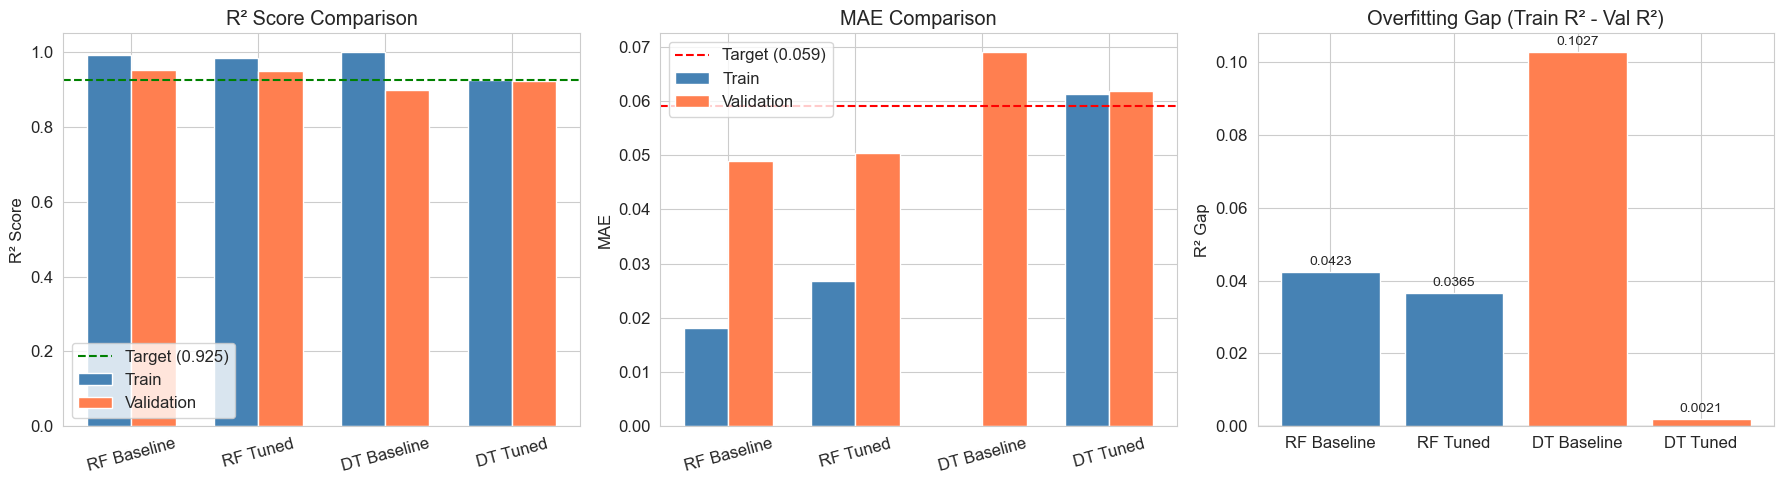

In [25]:
# 可视化对比：3 张子图并排
fig, axes = plt.subplots(1, 3, figsize=(18, 5))  # 1 行 3 列子图

# —— 第 1 张：R² 对比 ——
models = ['RF Baseline', 'RF Tuned', 'DT Baseline', 'DT Tuned']  # 4 个模型的名字
r2_train_vals = [rf_base_r2_train, rf_final_r2_train, dt_base_r2_train, dt_final_r2_train]  # 训练集 R²
r2_val_vals = [rf_base_r2_val, rf_final_r2_val, dt_base_r2_val, dt_final_r2_val]  # 验证集 R²

x = np.arange(len(models))  # x 坐标 [0,1,2,3]
width = 0.35  # 每根柱子的宽度（两根柱子一组，各占一半）

axes[0].bar(x - width/2, r2_train_vals, width, label='Train', color='steelblue')  # 训练集柱子（偏左）
axes[0].bar(x + width/2, r2_val_vals, width, label='Validation', color='coral')  # 验证集柱子（偏右）
axes[0].axhline(y=0.925, color='green', linestyle='--', label='Target (0.925)')  # 画达标线（绿色虚线）
axes[0].set_xticks(x)  # 设置 x 轴刻度位置
axes[0].set_xticklabels(models, rotation=15)  # 刻度名字并旋转 15 度
axes[0].set_title('R² Score Comparison')  # 标题
axes[0].set_ylabel('R² Score')  # y 轴
axes[0].legend()  # 图例

# —— 第 2 张：MAE 对比 ——
mae_train_vals = [rf_base_mae_train, rf_final_mae_train, dt_base_mae_train, dt_final_mae_train]  # 训练集 MAE
mae_val_vals = [rf_base_mae_val, rf_final_mae_val, dt_base_mae_val, dt_final_mae_val]  # 验证集 MAE

axes[1].bar(x - width/2, mae_train_vals, width, label='Train', color='steelblue')  # 训练集柱子
axes[1].bar(x + width/2, mae_val_vals, width, label='Validation', color='coral')  # 验证集柱子
axes[1].axhline(y=0.059, color='red', linestyle='--', label='Target (0.059)')  # MAE 达标线
axes[1].set_xticks(x)  # 刻度
axes[1].set_xticklabels(models, rotation=15)  # 名字
axes[1].set_title('MAE Comparison')  # 标题
axes[1].set_ylabel('MAE')  # y 轴
axes[1].legend()  # 图例

# —— 第 3 张：过拟合程度（训练 R² − 验证 R²，越大越过拟合）——
overfit_gap = [  # 四个模型的过拟合差距
    rf_base_r2_train - rf_base_r2_val,  # RF 基线
    rf_final_r2_train - rf_final_r2_val,  # RF 调优
    dt_base_r2_train - dt_base_r2_val,  # DT 基线
    dt_final_r2_train - dt_final_r2_val  # DT 调优
]  # 过拟合差距列表结束
bars = axes[2].bar(models, overfit_gap, color=['steelblue', 'steelblue', 'coral', 'coral'])  # 柱状图
axes[2].set_title('Overfitting Gap (Train R² - Val R²)')  # 标题
axes[2].set_ylabel('R² Gap')  # y 轴
axes[2].axhline(y=0, color='black', linewidth=0.8)  # 0 参考线
for bar, val in zip(bars, overfit_gap):  # 在每个柱子上标数值
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,  # 文字放在柱顶略上方
                f'{val:.4f}', ha='center', fontsize=10)  # 居中显示数值

plt.tight_layout()  # 调整布局
plt.show()  # 显示


## 7. 特征重要性分析

使用随机森林的 `feature_importances_` 分析哪些因素对 PUBG 获胜最重要。

In [26]:
# 提取特征重要性
feature_names = X_train.columns  # 所有特征的名字
rf_importances = rf_final.feature_importances_  # 随机森林自带：每个特征的重要性分数（越大越重要）

# 创建重要性 DataFrame 并排序
df_importance = pd.DataFrame({  # 特征名 + 重要性 组成表格
    'Feature': feature_names,  # 特征名
    'Importance': rf_importances  # 重要性分数
}).sort_values('Importance', ascending=False)  # 按重要性从高到低排序

df_importance['Importance_Pct'] = (df_importance['Importance'] * 100).round(2)  # 转成百分比，保留 2 位小数

# 显示 Top 15
print('=' * 60)  # 分隔线
print('         Random Forest — Top 15 Feature Importances')  # 标题
print('=' * 60)  # 分隔线
print(df_importance.head(15).to_string(index=False))  # 打印前 15 行，不带索引
print('=' * 60)  # 分隔线

# 累计重要性：前 15 个特征贡献了多少
top15_cumsum = df_importance['Importance'].head(15).sum()  # 前 15 个重要性求和
print(f'\nTop 15 特征累计重要性: {top15_cumsum*100:.1f}%')  # 转百分比打印


         Random Forest — Top 15 Feature Importances
          Feature  Importance  Importance_Pct
    totalDistance    0.148136           14.81
     walkDistance    0.142311           14.23
   killPlaceRatio    0.120879           12.09
        killPlace    0.108650           10.86
team_walkDistance    0.097265            9.73
      team_boosts    0.066051            6.61
   team_killPlace    0.053606            5.36
           boosts    0.048345            4.83
  weaponsAcquired    0.037367            3.74
    survivalScore    0.037140            3.71
            heals    0.012757            1.28
   playersInGroup    0.012752            1.28
      longestKill    0.011637            1.16
       team_heals    0.009650            0.97
team_rideDistance    0.009247            0.92

Top 15 特征累计重要性: 91.6%


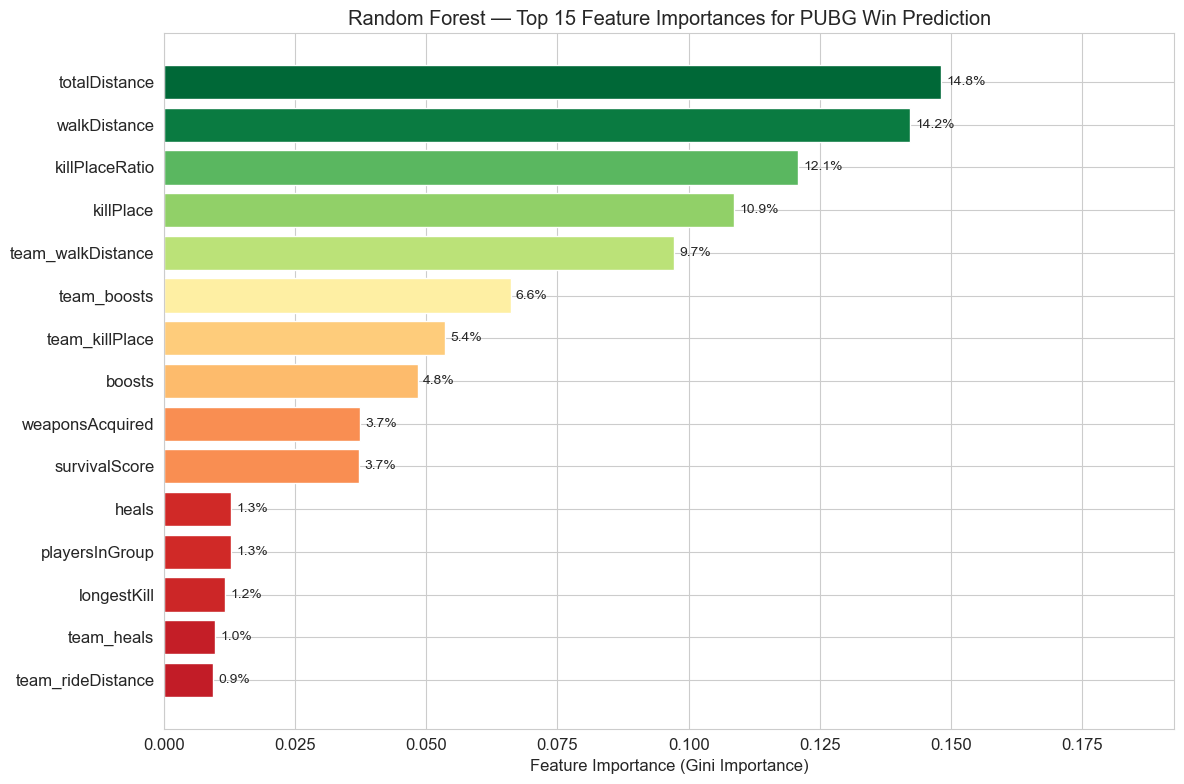

In [27]:
# Top 15 特征重要性柱状图
top15_rf = df_importance.head(15).iloc[::-1]  # 取前 15 再反转（让重要性高的显示在上方）

fig, ax = plt.subplots(figsize=(12, 8))  # 新建画布

colors = plt.cm.RdYlGn(top15_rf['Importance'] / top15_rf['Importance'].max())  # 按重要性大小映射红黄绿色
bars = ax.barh(top15_rf['Feature'], top15_rf['Importance'], color=colors)  # barh 画横向柱状图

for bar, val in zip(bars, top15_rf['Importance']):  # 每根柱子旁标数值
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,  # 文字位置：柱子右端外侧、垂直居中
            f'{val*100:.1f}%', va='center', fontsize=10)  # 百分比文本

ax.set_xlabel('Feature Importance (Gini Importance)')  # x 轴
ax.set_title('Random Forest — Top 15 Feature Importances for PUBG Win Prediction')  # 标题
ax.set_xlim(0, top15_rf['Importance'].max() * 1.3)  # x 轴留 30% 空间放数值文字
plt.tight_layout()  # 布局
plt.show()  # 显示


In [28]:
# 决策树特征重要性（作为对比）
dt_importances = dt_final.feature_importances_  # 决策树的重要性分数

df_dt_importance = pd.DataFrame({  # 组表
    'Feature': feature_names,  # 特征名
    'Importance': dt_importances  # 重要性
}).sort_values('Importance', ascending=False)  # 降序

print('=' * 60)  # 分隔线
print('         Decision Tree — Top 15 Feature Importances')  # 标题
print('=' * 60)  # 分隔线
print(df_dt_importance.head(15).to_string(index=False))  # Top 15
print('=' * 60)  # 分隔线

# 对比两种模型前 15 名的交集
rf_top15 = set(df_importance.head(15)['Feature'])  # RF 前 15 名（集合）
dt_top15 = set(df_dt_importance.head(15)['Feature'])  # DT 前 15 名（集合）
common_top15 = rf_top15 & dt_top15  # 交集：两个模型都看重的特征
rf_only = rf_top15 - dt_top15  # 差集：只有 RF 看重的
dt_only = dt_top15 - rf_top15  # 只有 DT 看重的

print(f'\n两种模型 Top 15 共同特征: {len(common_top15)} 个')  # 共同数量
print(f'共同特征: {sorted(common_top15)}')  # 共同名单
if rf_only:  # 非空才打印
    print(f'仅随机森林 Top 15: {sorted(rf_only)}')  # 打印仅随机森林看重的特征
if dt_only:  # 决策树独有特征非空时才打印
    print(f'仅决策树 Top 15: {sorted(dt_only)}')  # 打印仅决策树看重的特征


         Decision Tree — Top 15 Feature Importances
          Feature  Importance
    totalDistance    0.699582
   killPlaceRatio    0.193995
   team_killPlace    0.042969
team_walkDistance    0.032637
    matchDuration    0.006979
      team_boosts    0.006284
        killPlace    0.004309
   killEfficiency    0.004234
      killStreaks    0.002032
     walkDistance    0.001813
            DBNOs    0.001119
       team_kills    0.000775
        numGroups    0.000580
     rideDistance    0.000456
         maxPlace    0.000414

两种模型 Top 15 共同特征: 7 个
共同特征: ['killPlace', 'killPlaceRatio', 'team_boosts', 'team_killPlace', 'team_walkDistance', 'totalDistance', 'walkDistance']
仅随机森林 Top 15: ['boosts', 'heals', 'longestKill', 'playersInGroup', 'survivalScore', 'team_heals', 'team_rideDistance', 'weaponsAcquired']
仅决策树 Top 15: ['DBNOs', 'killEfficiency', 'killStreaks', 'matchDuration', 'maxPlace', 'numGroups', 'rideDistance', 'team_kills']


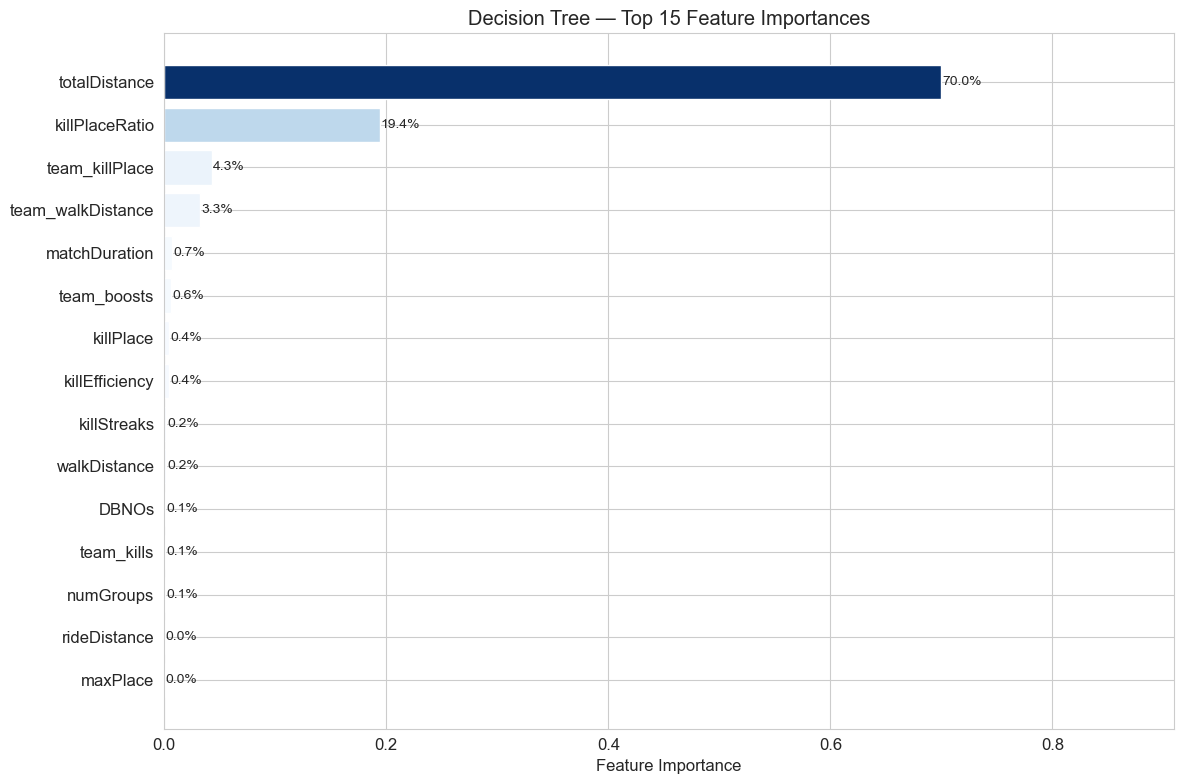

In [31]:
# 决策树 Top 15 柱状图
top15_dt = df_dt_importance.head(15).iloc[::-1]  # 前 15 反转（重要在上）

fig, ax = plt.subplots(figsize=(12, 8))  # 画布

colors = plt.cm.Blues(top15_dt['Importance'] / top15_dt['Importance'].max())  # 蓝色系渐变
bars = ax.barh(top15_dt['Feature'], top15_dt['Importance'], color=colors)  # 横向柱

for bar, val in zip(bars, top15_dt['Importance']):  # 标数值
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,  # 柱右外侧垂直居中
            f'{val*100:.1f}%', va='center', fontsize=10)  # 百分比

ax.set_xlabel('Feature Importance')  # x 轴
ax.set_title('Decision Tree — Top 15 Feature Importances')  # 标题
ax.set_xlim(0, top15_dt['Importance'].max() * 1.3)  # 留空间
plt.tight_layout()  # 布局
plt.show()  # 显示


## 8. 最终结论

### 8.1 哪些特征对 PUBG 获胜最重要？

根据随机森林特征重要性排序，结合游戏机制解读。

=== 特征重要性按类别汇总 ===
  移动活动: 29.4% (Top: totalDistance, walkDistance, rideDistance)
  团队/队伍: 25.9% (Top: team_walkDistance, team_boosts, team_killPlace)
  比赛规模/相对位置: 14.1% (Top: killPlaceRatio, playersInGroup, matchTotalKills)
  战斗能力: 13.9% (Top: killPlace, longestKill, kills)
  支援/治疗: 6.3% (Top: boosts, heals, assists)
  生存/对局: 5.9% (Top: survivalScore, matchDuration, numGroups)
  装备收集: 3.7% (Top: weaponsAcquired, vehicleDestroys)
  排名分: 0.5% (Top: rankPoints, killPoints, winPoints)
  游戏模式: 0.3% (Top: matchType_squad-fpp, matchType_solo-fpp, matchType_squad)
  负面行为: 0.0% (Top: teamKills)


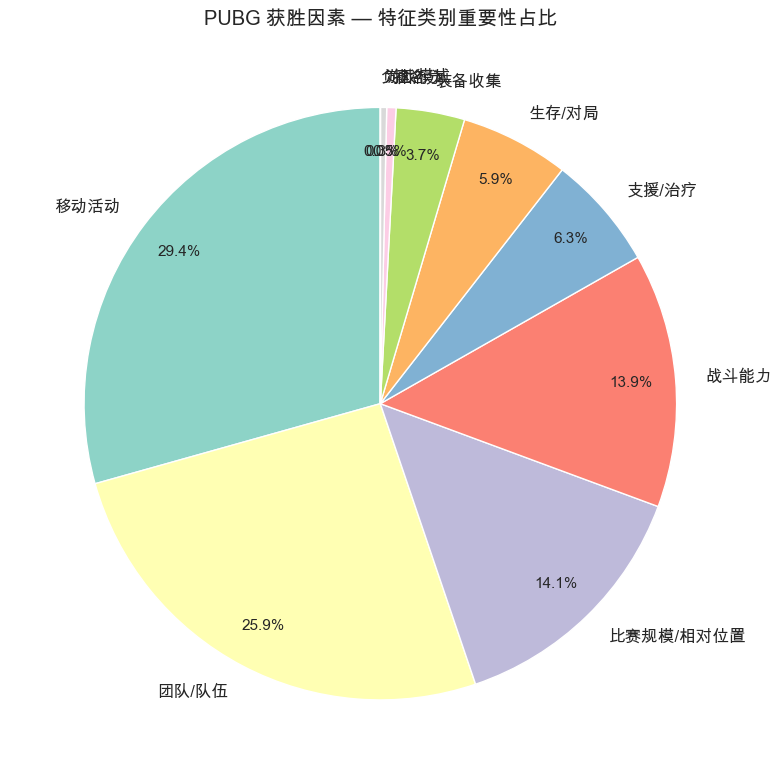

In [34]:
# 分类特征重要性
# 若单独重跑本 cell，需确保中文字体配置生效（import cell 中有相同配置）
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB', 'SimHei', 'Microsoft YaHei']  # 中文字体
plt.rcParams['axes.unicode_minus'] = False  # 负号正常显示

def classify_feature(feat_name):  # 定义函数：把特征名映射到游戏机制类别
    """将特征分类为游戏机制类别"""
    combat = ['kills', 'killPlace', 'damageDealt', 'headshotKills', 'killStreaks',  # 战斗能力：击杀/击杀排名/伤害/爆头/连杀/击倒/最远击杀/压路击杀/击杀效率
              'DBNOs', 'longestKill', 'roadKills', 'killEfficiency']  # 战斗能力类
    support = ['assists', 'revives', 'heals', 'boosts', 'teamContribution']  # 支援/治疗类
    movement = ['walkDistance', 'rideDistance', 'swimDistance', 'totalDistance']  # 移动活动类
    items = ['weaponsAcquired', 'vehicleDestroys']  # 装备收集类
    ranking = ['winPoints', 'killPoints', 'rankPoints']  # 排名分类
    survival = ['survivalScore', 'matchDuration', 'maxPlace', 'numGroups']  # 生存/对局类
    negative = ['teamKills']  # 负面行为类
    mode = [c for c in feature_names if c.startswith('matchType_')]  # 模式独热列（matchType_ 开头）

    # 聚合特征分类（2.5 构造）
    if feat_name.startswith('team_'):  # team_ 开头 -> 团队/队伍
        return '团队/队伍'  # 命中则返回该类别
    if feat_name in ['playersInGroup', 'playersInMatch', 'matchTotalKills', 'killPlaceRatio']:  # 规模/位置类
        return '比赛规模/相对位置'  # 命中则返回该类别
    if feat_name.endswith('_missing'):  # 缺失指示列 -> 排名分
        return '排名分'  # 命中则返回该类别

    if feat_name in combat: return '战斗能力'  # 命中战斗列表
    if feat_name in support: return '支援/治疗'  # 命中支援类
    if feat_name in movement: return '移动活动'  # 命中移动类
    if feat_name in items: return '装备收集'  # 命中装备类
    if feat_name in ranking: return '排名分'  # 命中排名分类
    if feat_name in survival: return '生存/对局'  # 命中生存类
    if feat_name in negative: return '负面行为'  # 命中负面行为
    if feat_name in mode: return '游戏模式'  # 命中模式列
    return '其他'  # 都不匹配的兜底

df_importance['Category'] = df_importance['Feature'].apply(classify_feature)  # 给每个特征打上类别标签

# 按类别汇总重要性
category_importance = df_importance.groupby('Category')['Importance'].sum().sort_values(ascending=False)  # 同类别求和，降序

print('=== 特征重要性按类别汇总 ===')  # 标题
for cat, imp in category_importance.items():  # 遍历每个类别
    top_feats = df_importance[df_importance['Category'] == cat].head(3)['Feature'].tolist()  # 该类前 3 个特征
    print(f'  {cat}: {imp*100:.1f}% (Top: {", ".join(top_feats)})')  # 类别占比 + Top 特征

# 绘制类别重要性饼图
fig, ax = plt.subplots(figsize=(10, 8))  # 画布
colors_pie = plt.cm.Set3(range(len(category_importance)))  # 生成一组区分度高的颜色
wedges, texts, autotexts = ax.pie(  # 画饼图；返回：扇区、标签文本、百分比文本
    category_importance.values,  # 每类的数值
    labels=category_importance.index,  # 每类的名称
    autopct='%1.1f%%',  # 在扇区上显示百分比
    colors=colors_pie,  # 颜色
    startangle=90,  # 从 90 度开始画
    pctdistance=0.85  # 百分比文字离中心的距离
)  # 结束 ax.pie(...) 调用
for autotext in autotexts:  # 统一调百分比字号
    autotext.set_fontsize(11)  # 把百分比文字字号统一设为 11
ax.set_title('PUBG 获胜因素 — 特征类别重要性占比')  # 标题
plt.tight_layout()  # 布局
plt.show()  # 显示


### 8.2 总结

**关键发现**：

1. **移动活动是最重要的获胜因素** — 实测特征重要性中，移动活动类（`walkDistance`、`totalDistance`、`rideDistance` 等）占比约 29% 最高，其次为团队聚合特征（约 25%）与战斗能力（`killPlace`、`longestKill` 等，约 15%）。跑图积极、持续移动的玩家排名更高。

2. **移动活动反映玩家活跃度** — `walkDistance` 和 `totalDistance`（新构造特征）表明跑图积极、搜索资源的玩家排名更高。

3. **支援能力在团队模式中不可忽视** — `boosts`, `heals`, `assists`, `revives` 体现团队协作和生存续航能力。

4. **随机森林 vs 决策树**：
   - 随机森林通过集成学习显著优于单棵决策树（Val R² 0.9489 vs 0.9229，MAE 0.0504 vs 0.0619）
   - 随机森林训练-验证差距小（0.9854 vs 0.9489，差距 0.0365），泛化稳定
   - 决策树训练快、可解释性好，但单棵树拟合能力有限（训练-验证差距仅 0.002，属容量不足而非过拟合），在强噪声的赛局数据上难以进一步提升

5. **新构造特征的效果**：
   - `team_*` 聚合特征: 队伍整体表现（总伤害/总击杀/队内人数）是个人排名的强信号，与移动活动特征合计解释约 54% 的重要性
   - `playersInMatch`: 比赛参与人数，直接决定 winPlacePerc 的分布
   - `totalDistance`: 综合移动距离，可能比单独的 walk/ride/swim 更有预测力
   - `killEfficiency`: 反映枪法精准度
   - `teamContribution`: 团队协作指标
   - `survivalScore`: 区分激进刚枪 vs 保守苟分风格

**改进方向**：
- 尝试 XGBoost / LightGBM 梯度提升模型，通常在大规模表格数据上表现更好
- 考虑使用 matchType 分组建模（solo/duo/squad 的游戏逻辑不同）